![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 3. Interferometers I - MZI


Today we will work on the design and modeling of an **Mach-Zenhder Interferometer (MZI)** used in integrated photonic circuits. We will perform simulations that will allow us to understand how it operates.


## 0.1 General libraries

In [1]:
import gdsfactory as gf
import jax
import jax.example_libraries.optimizers as opt
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

import numpy as np
import sax
from gdsfactory.generic_tech import get_generic_pdk
from scipy import constants
from scipy.constants import c
from scipy.interpolate import interp1d

import gplugins.sax as gs
from gplugins.common.config import PATH

C:\Users\andre\AppData\Local\Temp\ipykernel_12020\3896563056.py:10: DeprecationWarning: The 'gdsfactory.generic_tech' module is deprecated and will be removed in a future version. Please update your imports to use 'gdsfactory.gpdk' instead:
  from gdsfactory.gpdk import LAYER, LAYER_STACK, get_generic_pdk
Or for submodules:
  from gdsfactory.gpdk.layer_map import LAYER
  from gdsfactory.gpdk.layer_stack import LAYER_STACK
  from gdsfactory.generic_tech import get_generic_pdk


## 1. MZI modeling
Let's compute the transfer function of a MZI

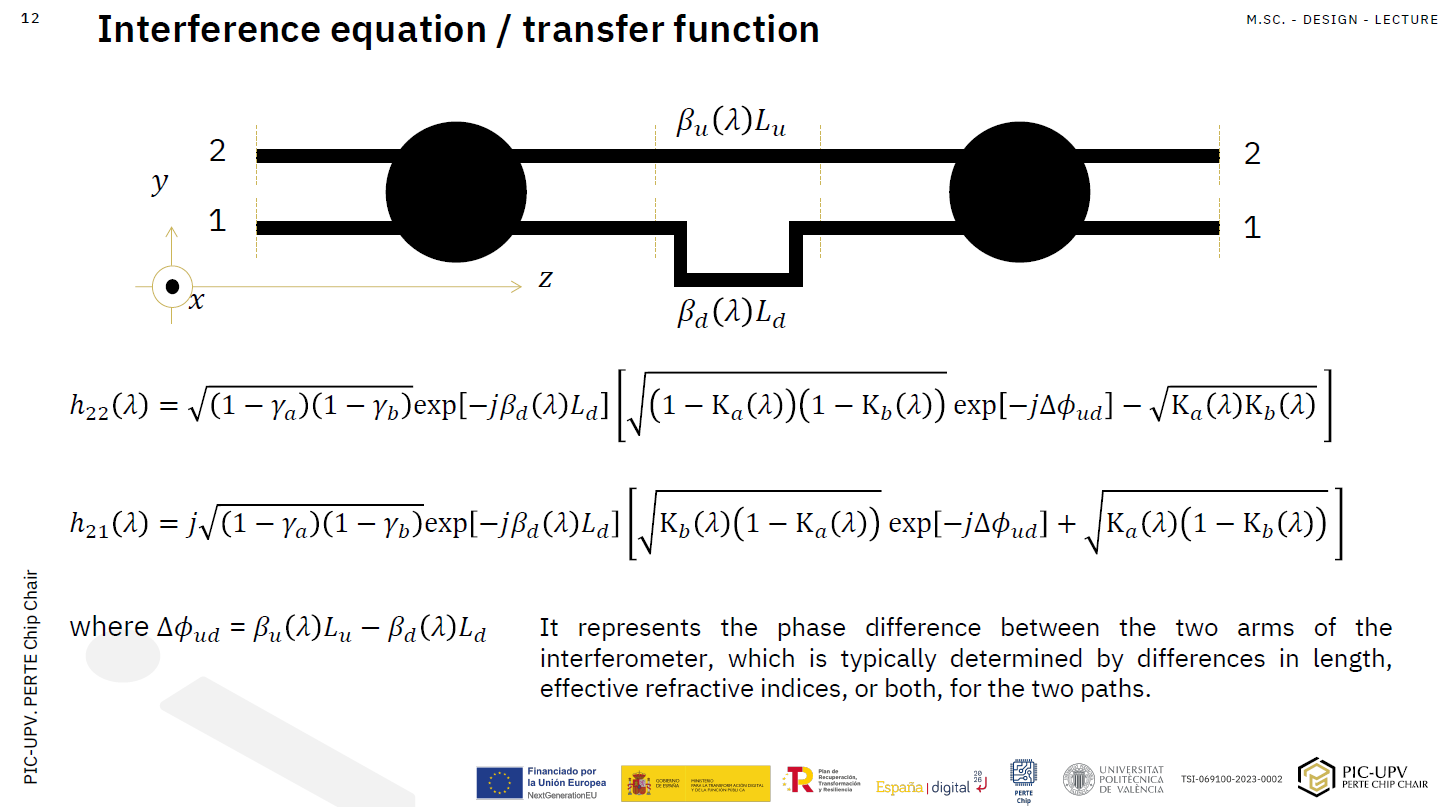

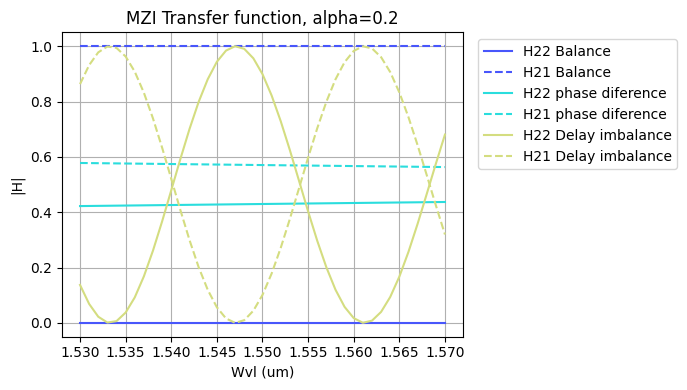

In [ ]:
### Waveguides configuration ###

## Propagation parameters

## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode)
neffd = SOI[:, 3] #balanced configuration // (neff TE mode)

## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #unbalanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #unbalanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')

neffu1 = interp_neffu(wvl)
neffd1 = interp_neffd(wvl)   #esto para el caso unbalance

#---------------------------balance-------------------------------------
alphau = 0; #losless case [dB/um]
alphad = 0; #losless case [dB/um]

gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss


alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um
Lu = 15; # um
Ld = 15; # um
betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np
Delta_phi_ud = betau*Lu - betad*Ld


K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

H21 = np.abs(h_21) ** 2
H22 = np.abs(h_22) ** 2


#--------------------------phase difeference----------------

# Path length
Lu = 11; # um
Ld = 11; # um

betau = (2*jnp.pi/wvl)*neffu1-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd1-1j*alphad_np
Delta_phi_ud = betau*Lu - betad*Ld

h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

H21_p = np.abs(h_21) ** 2
H22_p = np.abs(h_22) ** 2

#-------------------------delay------------------------

Lu = 25; # um
Ld = 5; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np
Delta_phi_ud = betau*Lu - betad*Ld

h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

H21_d = np.abs(h_21) ** 2
H22_d = np.abs(h_22) ** 2


# Plot
color = cm.rainbow(np.linspace(0, 1, 10))
plt.figure(figsize=(7, 4))
plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22 Balance')
plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21 Balance ')

plt.plot(wvl, H22_p, linestyle='-', color=color[3], label='H22 phase diference')
plt.plot(wvl, H21_p, linestyle='--', color=color[3], label='H21 phase diference')

plt.plot(wvl, H22_d, linestyle='-', color=color[6], label='H22 Delay imbalance')
plt.plot(wvl, H21_d, linestyle='--', color=color[6], label='H21 Delay imbalance')

plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function, alpha=0.2')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.grid(True)

plt.show()

**Assesment 1.** Please, provide one example of each one of the configurations studied during MZI lecture:
1. Balenced configuration
2. Unbalanced configuration
  1.   Phase difference
  2.   Delay imbalance

**Assesment 2.** Taking into account the n_{eff} values for the SOI cross-section, what would be the path difference ($\Delta L$ = $L_u$ - $L_d$) needed to obtain a Free Spectral Range of 40 nm? Introduce the obtained value in the model to check the MZI response. Hint: We assume 1550 nm as the central design wavelength ($\lambda _0$=1550 nm).

wvl = 1.53 ng = 4.321999999999725
wvl = 1.531 ng = 4.329749999999831
wvl = 1.532 ng = 4.337500000000352
wvl = 1.533 ng = 4.337500000000352
wvl = 1.534 ng = 4.337499999999648
wvl = 1.535 ng = 4.329750000000184
wvl = 1.536 ng = 4.329750000000184
wvl = 1.537 ng = 4.3375
wvl = 1.538 ng = 4.3375
wvl = 1.539 ng = 4.337500000000352
wvl = 1.54 ng = 4.3375
wvl = 1.541 ng = 4.3375
wvl = 1.542 ng = 4.337499999999648
wvl = 1.543 ng = 4.329750000000184
wvl = 1.544 ng = 4.329750000000184
wvl = 1.545 ng = 4.3375
wvl = 1.546 ng = 4.337499999999648
wvl = 1.547 ng = 4.337500000000352
wvl = 1.548 ng = 4.3375
wvl = 1.549 ng = 4.337500000000352
wvl = 1.55 ng = 4.3375
wvl = 1.551 ng = 4.3375
wvl = 1.552 ng = 4.3375
wvl = 1.553 ng = 4.337500000000352
wvl = 1.554 ng = 4.3375
wvl = 1.555 ng = 4.337500000000352
wvl = 1.556 ng = 4.337499999999648
wvl = 1.557 ng = 4.3375
wvl = 1.558 ng = 4.3375
wvl = 1.559 ng = 4.3375
wvl = 1.56 ng = 4.337499999999648
wvl = 1.561 ng = 4.3375
wvl = 1.562 ng = 4.345249999999817
wvl

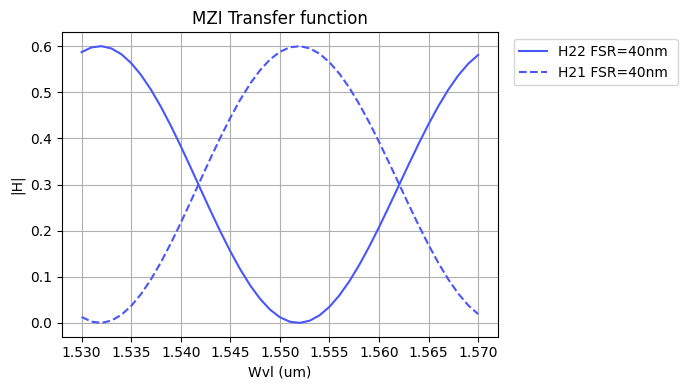

In [3]:
dneff = np.gradient(neffu, wvl)
neff0 = 2.4  
lamda0=1.55

ng   = neff0 - lamda0*dneff 
for i, w in enumerate(wvl):
    print("wvl =", w, "ng =", ng[i])

ng_155= 4.3375
L  =  1.55**2 / (ng_155 * 0.04)
print("diff_L=", L)  #48,05um


Lu = 5; # um
Ld = 5+L; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np
Delta_phi_ud = betau*Lu - betad*Ld

# Excess loss
gamma_a = 0.4; #null excess loss
gamma_b = 0; #null excess loss
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

H21_fsr = np.abs(h_21) ** 2
H22_fsr = np.abs(h_22) ** 2


# Plot
color = cm.rainbow(np.linspace(0, 1, 10))
plt.figure(figsize=(7, 4))
plt.plot(wvl, H22_fsr, linestyle='-', color=color[1], label='H22 FSR=40nm')
plt.plot(wvl, H21_fsr, linestyle='--', color=color[1], label='H21 FSR=40nm ')

plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.grid(True)

## 2. MZI simulation implemented with SAX
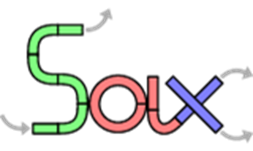

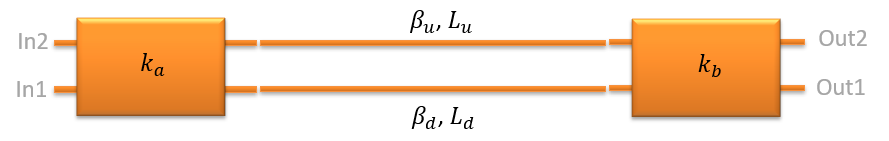


### 2.1 Components S matrix


In [4]:
# Waveguide Model

def waveguide(wl=1.55, neff=1.6072, length=10.0, loss=0.0) -> sax.SDict:
    phase = 2 * jnp.pi * neff * length / wl
    transmission = 10 ** (-loss * length / 20) * jnp.exp(1j * phase) # loss(dB/um)
    wg_dict = sax.reciprocal(
        {
            ("in0", "out0"): transmission,
        }
    )
    return wg_dict


# Coupler Model

def coupler(coupling=0.5) -> sax.SDict:
    kappa = coupling**0.5
    tau = (1 - coupling) ** 0.5
    coupler_dict = sax.reciprocal(
        {
            ("in0", "out0"): tau,
            ("in0", "out1"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out0"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out1"): tau,
        }
    )
    return coupler_dict

### 2.2 MZI SAX Circuit Model

In [5]:
# MZI

mzi, info = sax.circuit(
    netlist={
        "instances": {
            "coup_a": "coupler",
            "wvg_u": "waveguide",
            "wvg_d": "waveguide",
            "coup_b": "coupler",
        },
        "connections": {
            "coup_a,out0": "wvg_d,in0",
            "wvg_d,out0": "coup_b,in0",
            "coup_a,out1": "wvg_u,in0",
            "wvg_u,out0": "coup_b,in1",
        },
        "ports": {
            "in0": "coup_a,in0",
            "in1": "coup_a,in1",
            "out0": "coup_b,out0",
            "out1": "coup_b,out1",
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)


### 2.3. MZI Modeling
**Assesment 3**: Now, we are going to implement the design parameters in the MZI model developed in SAX and compare the response obtained with that simulated by mathematical formulation.

This will help us to identify any error in the definition of the SAX model single components.

In order to implement the SAX model, take as example the following lines:

    mzi_test = mzi(wl=wl,
                coup_a = ...
                wvg_d={"length": l_d, "neff": ...},
                wvg_u={"length": l_u, "neff": ...},
                coup_b = ... )

    H00 = mzi_test["in0", "out0"]


**Assessment 4.** Designing an MZI for filtering at a specific wavelength. Calculate and adjust the arm lengths to configure the MZI to have a maximum transmission at 1550 nm.

**Assessment 5.** Let's see how the response of the MZI variates with the effective index. Vary the effective index of one of the arms and analyze how the spectrum shifts. To do this, you can use the data provided in the .txt files entitled ‘SiN’.
Can you give an example of an application where this configuration is used?

**Assessment 6.** Explore how cascading two MZIs affects the transmission spectrum. To do so, design a system in which two MZIs are cascaded. Simulate and observe the spectrum, explaining how the transmission peaks behave.

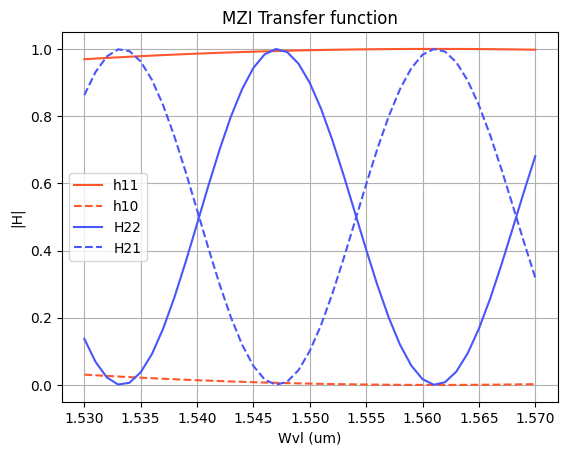

In [111]:
Lu=25
Ld=24
mzi_test = mzi(wl=wvl,
            coup_a={"coupling":K_a},
            wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_b={"coupling":K_b},
            )

h00 = mzi_test["in0", "out0"]
h01 = mzi_test["in0", "out1"]
h11 = mzi_test["in1", "out1"]
h10 = mzi_test["in1", "out0"]


# Plot
plt.figure()
plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
plt.plot(wvl, H22_d, linestyle='-', color=color[1], label='H22')
plt.plot(wvl, H21_d, linestyle='--', color=color[1], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.legend()
plt.title('MZI Transfer function')
plt.grid(True)
plt.show()


10.0
16.579589688297244
23.159179376594487
29.738769064891734
36.318358753188974
42.89794844148622
49.47753812978347
56.05712781808071
10.0
16.579589688297244
23.159179376594487
29.738769064891734


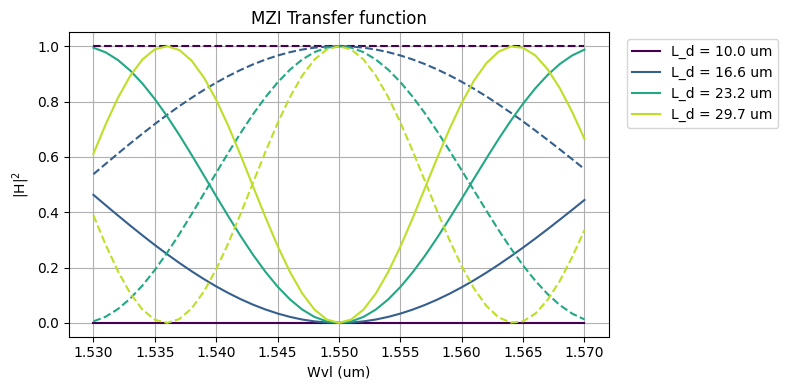

In [108]:
Lu = 10
Ld = 10

H00, H01, H10, H11 = [], [], [], []
#dl= lamda*m / neff(1.55)
#1.6072
neff_sax=2.35577
#print(neff0)
for i in np.arange(0, 8):             
    Ld2 = Ld + (Ld * i* 1.55 / neff_sax)
    print(Ld2)
    mzi_test = mzi(wl=wvl,
                   coup_a={"coupling": K_a},
                   wvg_u={"wl": wvl, "neff": neffu, "length": Lu,  "loss": alphau},
                   wvg_d={"wl": wvl, "neff": neffd, "length": Ld2, "loss": alphad},
                   coup_b={"coupling": K_b},
                   )

    H00.append(mzi_test["in0", "out0"])
    H01.append(mzi_test["in0", "out1"])
    H10.append(mzi_test["in1", "out0"])
    H11.append(mzi_test["in1", "out1"])

ks = [0, 1, 2,3]                     
colors = cm.viridis(np.linspace(0, 0.9, len(ks)))

plt.figure(figsize=(8, 4))
for k, c in zip(ks, colors):
    Ld2 = Ld + (Ld * k* 1.55 / neff_sax)
    print(Ld2)
    plt.plot(wvl, np.abs(H11[k])**2, linestyle="-",  color=c, label=f"L_d = {Ld2:.1f} um")
    plt.plot(wvl, np.abs(H10[k])**2, linestyle="--", color=c)

plt.xlabel('Wvl (um)')
plt.ylabel('|H|$^2$')
plt.title('MZI Transfer function')
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()
plt.show()

indice efectivo con SiN_cladding:  1.574130486
distancia brazo inferior:  10.0
distancia brazo inferior:  19.846705935660278
distancia brazo inferior:  29.693411871320556
distancia brazo inferior:  39.54011780698084
distancia brazo inferior:  49.38682374264111
distancia brazo inferior:  59.233529678301394
distancia brazo inferior:  69.08023561396168
distancia brazo inferior:  78.92694154962196
distancia brazo inferior:  88.77364748528223
distancia brazo inferior:  98.62035342094251
distancia brazo inferior:  108.46705935660279
distancia brazo inferior:  118.31376529226307
distancia brazo inferior:  128.16047122792335


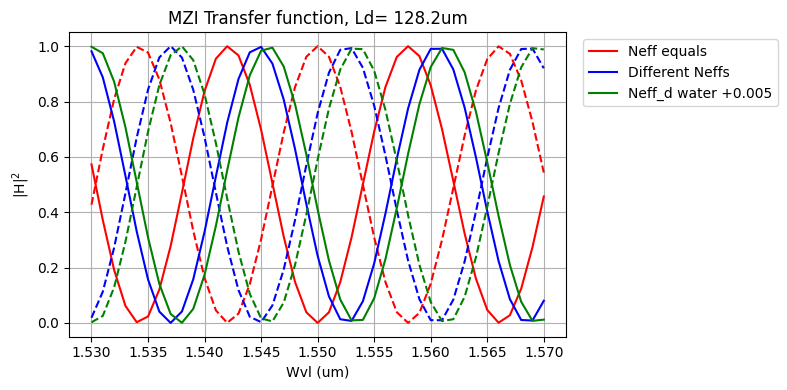

In [90]:
Lu = 10
Ld = 10
#neffu1  para cladding
#neffd1  para water 
neff_c = np.interp(1.55, wvl0, neffu0)
print("indice efectivo con SiN_cladding: ", neff_c)
for i in np.arange(0, 13):             
    Ld2 = Ld + (Ld * i* 1.55 / neff_c)
    print("distancia brazo inferior: ", Ld2)
Ld= 88.77364748528223
# caso con neff igual en ambos brazos
mzi_test = mzi(wl=wvl,
                   coup_a={"coupling": K_a},
                   wvg_u={"wl": wvl, "neff": neffu1, "length": Lu,  "loss": alphau},
                   wvg_d={"wl": wvl, "neff": neffu1, "length": Ld, "loss": alphad},
                   coup_b={"coupling": K_b},
                   )

H00=mzi_test["in0", "out0"]
H01=mzi_test["in0", "out1"]
H10=mzi_test["in1", "out0"]
H11=mzi_test["in1", "out1"]

#variacion de neff en el otro brazo
mzi_test = mzi(wl=wvl,
                   coup_a={"coupling": K_a},
                   wvg_u={"wl": wvl, "neff": neffu1, "length": Lu,  "loss": alphau},
                   wvg_d={"wl": wvl, "neff": neffd1, "length": Ld, "loss": alphad},
                   coup_b={"coupling": K_b},
                   )

H00_2=mzi_test["in0", "out0"]
H01_2=mzi_test["in0", "out1"]
H10_2=mzi_test["in1", "out0"]
H11_2=mzi_test["in1", "out1"]

# variacion pequeña en el neff inferior
neffd2= neffd1+0.001

mzi_test = mzi(wl=wvl,
                   coup_a={"coupling": K_a},
                   wvg_u={"wl": wvl, "neff": neffu1, "length": Lu,  "loss": alphau},
                   wvg_d={"wl": wvl, "neff": neffd2, "length": Ld, "loss": alphad},
                   coup_b={"coupling": K_b},
                   )

H00_3=mzi_test["in0", "out0"]
H01_3=mzi_test["in0", "out1"]
H10_3=mzi_test["in1", "out0"]
H11_3=mzi_test["in1", "out1"]



plt.figure(figsize=(8, 4))
plt.plot(wvl, np.abs(H11)**2, linestyle="-",  color="r", label="Neff equals")
plt.plot(wvl, np.abs(H10)**2, linestyle="--", color="r")
plt.plot(wvl, np.abs(H11_2)**2, linestyle="-",  color="b", label="Different Neffs")
plt.plot(wvl, np.abs(H10_2)**2, linestyle="--", color="b")
plt.plot(wvl, np.abs(H11_3)**2, linestyle="-",  color="g", label="Neff_d water +0.005")
plt.plot(wvl, np.abs(H10_3)**2, linestyle="--", color="g")
plt.xlabel('Wvl (um)')
plt.ylabel('|H|$^2$')
plt.title(f'MZI Transfer function, Ld= {Ld2:.1f}um')
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()
plt.show()





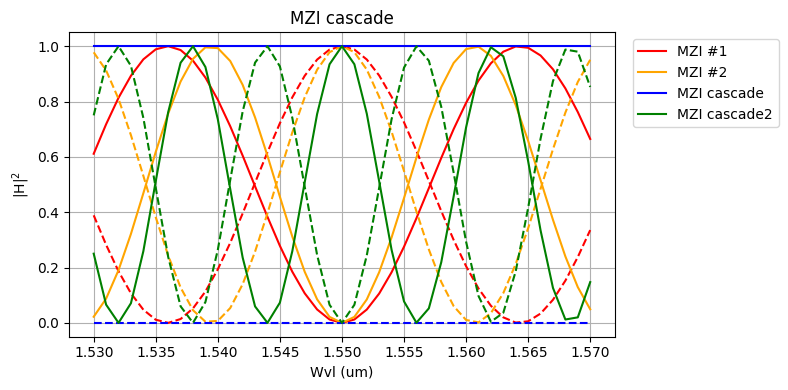

In [110]:
##Punto 6  :   Explore how cascading two MZIs affects the transmission spectrum. To do so, 
# design a system in which two MZIs are cascaded. Simulate and observe the spectrum, explaining how the transmission peaks behave.
Lu = 10
Ld = 29.738769064891734

mzi_test = mzi(wl=wvl,
                   coup_a={"coupling": K_a},
                   wvg_u={"wl": wvl, "neff": neffu, "length": Lu,  "loss": alphau},
                   wvg_d={"wl": wvl, "neff": neffd, "length": Ld, "loss": alphad},
                   coup_b={"coupling": K_b},
                   )
H00=mzi_test["in0", "out0"]
H01=mzi_test["in0", "out1"]
H10=mzi_test["in1", "out0"]
H11=mzi_test["in1", "out1"]


mzi_test_2 = mzi(wl=wvl,
                   coup_a={"coupling": K_a},
                   wvg_u={"wl": wvl, "neff": neffu, "length": 36.318358753188974,  "loss": alphau},#cambio de distancias
                   wvg_d={"wl": wvl, "neff": neffd, "length": Lu, "loss": alphad},
                   coup_b={"coupling": K_b},
                   )
H00_2=mzi_test_2["in0", "out0"]
H01_2=mzi_test_2["in0", "out1"]
H10_2=mzi_test_2["in1", "out0"]
H11_2=mzi_test_2["in1", "out1"]

M = np.array([[H00, H01],
              [H10, H11]])
M2 = np.array([[H00_2, H01_2],
              [H10_2, H11_2]])




# Multiplicar la matriz por sí misma
M3 = np.einsum('ikn,kjn->ijn', M, M)
M4 = np.einsum('ikn,kjn->ijn', M, M2)

H10_3 = M3[1, 0]
H11_3 = M3[1, 1]

H10_4 = M4[1, 0]
H11_4 = M4[1, 1]

plt.figure(figsize=(8, 4))
plt.plot(wvl, np.abs(H11)**2, linestyle="-",  color="r", label="MZI #1")
plt.plot(wvl, np.abs(H10)**2, linestyle="--", color="r")
plt.plot(wvl, np.abs(H11_2)**2, linestyle="-",  color="orange", label="MZI #2")
plt.plot(wvl, np.abs(H10_2)**2, linestyle="--", color="orange")

plt.plot(wvl, np.abs(H11_3)**2, linestyle="-",  color="b", label="MZI cascade")
plt.plot(wvl, np.abs(H10_3)**2, linestyle="--", color="b")
plt.plot(wvl, np.abs(H11_4)**2, linestyle="-",  color="g", label="MZI cascade2")
plt.plot(wvl, np.abs(H10_4)**2, linestyle="--", color="g")
plt.xlabel('Wvl (um)')
plt.ylabel('|H|$^2$')
plt.title('MZI cascade')
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()
plt.show()